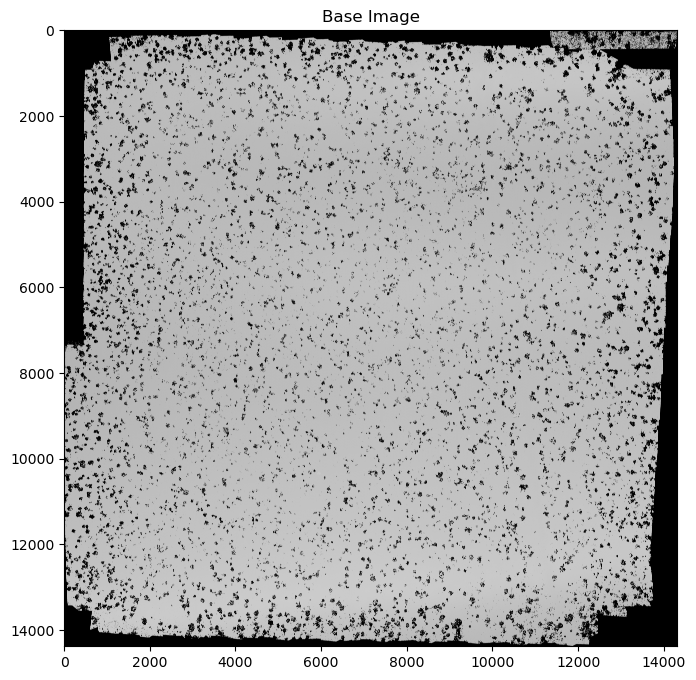

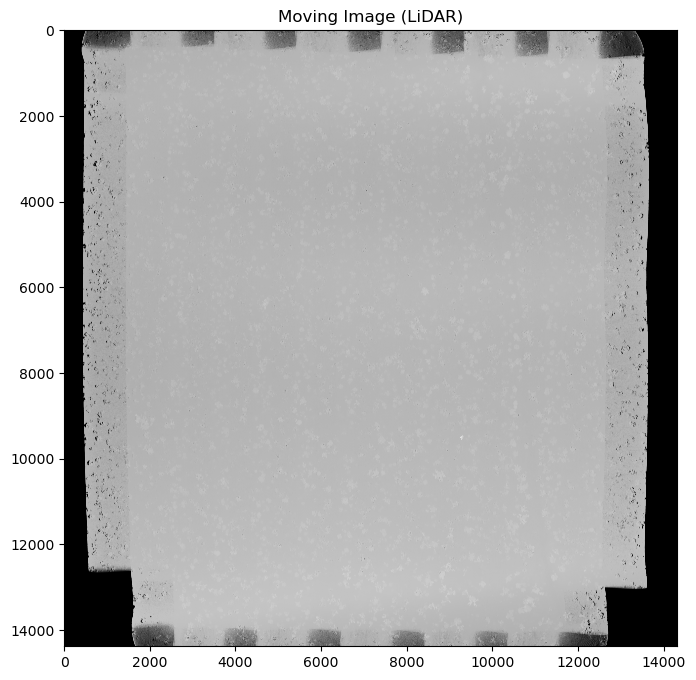

In [ ]:
import sys
import numpy as np
import rasterio
import time
import pylab as pl
from pathlib import Path

# === GeFolki dependencies === worksation
# sys.path.append('/media/laura/laura_usb/code/fvc_structure/phase_1_image_processing/gefolki/python')
# === GeFolki dependencies === NVIDIA
sys.path.append('/home/nvidia/projects/fvc_structure/phase_2_lidar_coregistration/gefolki/python')

from algorithm import EFolki
from tools import wrapData

# === Configuration ===
Base_band = 0

# === Input paths === workstation
# base_image_path = Path("/media/laura/laura_usb/uas_data/DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif")
# moving_image_path = Path("/media/laura/laura_usb/uas_data/DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif")


# === Input paths === NVIDIA
base_image_path = Path("/data/calperumResearch/site1_1_DD0001/imagery/dsm/SASMDD0001_rgb_dsm_03.tif")
moving_image_path = Path("/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03.tif")


# === Simplified and Corrected Load Function ===
def load_data_and_mask(path, band_idx):
    """
    Loads raster data and, crucially, also returns a boolean 'mask'
    that perfectly preserves the footprint of where the valid data is.
    """
    with rasterio.open(path) as src:
        if band_idx >= src.count:
            raise ValueError(f"Band {band_idx} is out of bounds.")
        
        # Get a True/False mask of the valid data footprint (255=valid, 0=nodata)
        valid_mask = src.read_masks(band_idx + 1) > 0   # Create mask
        
        # Read the data and set nodata areas to 0 for processing
        arr = src.read(band_idx + 1).astype(np.float32)  # Convert to float
        arr[~valid_mask] = 0    # Apply mask (sets nodata to 0)
        return arr, valid_mask

# === Load base and moving images, capturing their masks ===
base_data, base_mask = load_data_and_mask(base_image_path, Base_band)
moving_data, moving_mask = load_data_and_mask(moving_image_path, 0)

# === Plot initial data ===
pl.figure(figsize=(8,8)); pl.imshow(base_data, cmap='gray'); pl.title("Base Image")
pl.figure(figsize=(8,8)); pl.imshow(moving_data, cmap='gray'); pl.title("Moving Image (LiDAR)")
pl.show()

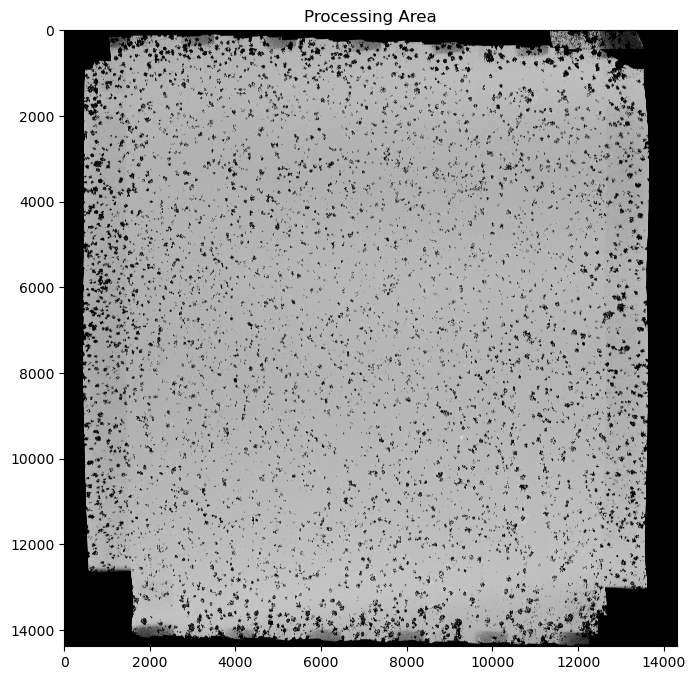

In [ ]:
# === Define processing area ===
# The area to process is where BOTH images have valid data
processing_mask = base_mask & moving_mask  # Common overlap
base_data[~processing_mask] = 0  # Set to 0 outside overlap
moving_data[~processing_mask] = 0

pl.figure(figsize=(8,8)); pl.imshow(moving_data, cmap='gray'); pl.title("Processing Area")
pl.show()

Calculating flow...



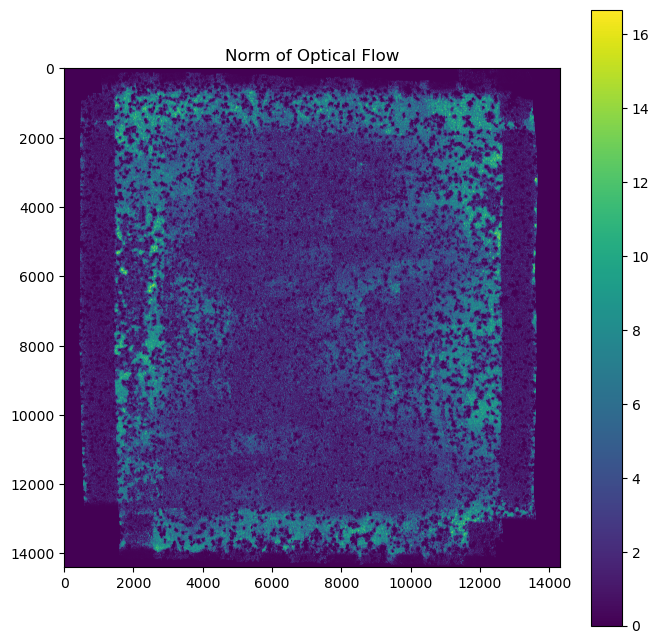

In [ ]:
# === Calculate optical flow ===
print("Calculating flow...\n")
t0 = time.perf_counter()
# --- BEFORE --- L1 displacement up to ~64 pixels
u, v = EFolki(base_data, moving_data, iteration=8, radius=[16, 8, 4], rank=4, levels=6)

# --- AFTER (for displacements > 64 pixels) ---
# Increased levels to 7 (handles up to 128px displacement)
# Added a larger radius '32' for the new, coarsest pyramid level
# u, v = EFolki(base_data, moving_data, 
#               iteration=8, 
#               radius=[32, 16, 8, 4],  # Adjust list size/values
#               rank=4, 
#               levels=7)              # Key change for large displacement
# t1 = time.perf_counter()
# print(f"✅ Flow calculated in {(t1 - t0)/60:.3f} minutes")

# Mask the flow vectors for cleaner plotting
u[~processing_mask] = 0
v[~processing_mask] = 0

N = np.sqrt(u**2 + v**2)
pl.figure(figsize=(8,8)); pl.imshow(N, cmap='viridis'); pl.title("Norm of Optical Flow"); pl.colorbar()
pl.show()

In [31]:
# === Load previously calculated flow fields ===
import numpy as np
from pathlib import Path

flow_dir = Path("/data/calperumResearch/site1_1_DD0001/imagery/dsm")
u = np.load(flow_dir / "flow_u_03_l1.npy")
v = np.load(flow_dir / "flow_v_03_l1.npy")

print(f"✅ Loaded flow fields from {flow_dir}")
print(f"   u shape: {u.shape}")
print(f"   v shape: {v.shape}")

✅ Loaded flow fields from /data/calperumResearch/site1_1_DD0001/imagery/dsm
   u shape: (14380, 14314)
   v shape: (14380, 14314)


Registering image...



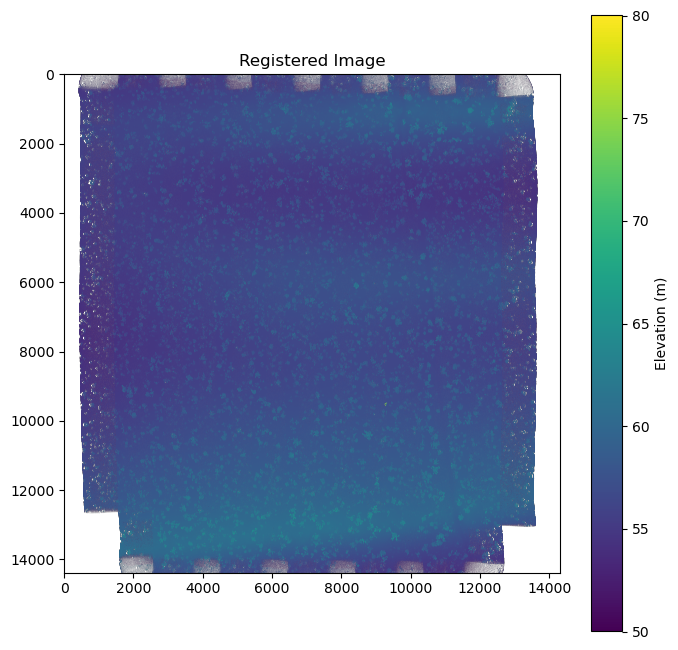

In [34]:
# === Register the LiDAR data AND its footprint ===
print("Registering image...\n")

# 1. Reload the ORIGINAL moving data (with real nodata values, not 0)
with rasterio.open(moving_image_path) as src:
    moving_data_original = src.read(1).astype(np.float32)
    original_nodata = src.nodata if src.nodata is not None else -9999.0

# 2. Warp the ORIGINAL LiDAR elevation data (with real nodata values)
imag_reg = wrapData(moving_data_original, u, v)

# 3. Warp the LiDAR's original footprint using the SAME flow field
warped_mask = wrapData(moving_mask.astype('float32'), u, v) > 0

# 4. Apply mask to set warped nodata areas
imag_reg[~warped_mask] = original_nodata

# 5. Create masked array for visualization
imag_reg_masked = np.ma.masked_equal(imag_reg, original_nodata)

pl.figure(figsize=(8,8))
im = pl.imshow(imag_reg_masked, cmap='viridis', vmin=50, vmax=80)
pl.title("Registered Image")
pl.colorbar(im, label='Elevation (m)')
pl.show()

In [ ]:
# === Save flow and the correctly registered image ===
print("\n--- Saving Results ---")
flow_dir = base_image_path.parent
aligned_path = moving_image_path.with_name(moving_image_path.stem + "_coreg.tif")

# 1. Get the metadata from the MOVING image (LiDAR source), not the base
with rasterio.open(moving_image_path) as src:
    profile = src.profile
    nodata_value = src.nodata if src.nodata is not None else -9999.0

print(f"Using nodata value: {nodata_value}")

# 2. Apply the warped mask to set nodata
imag_reg[~warped_mask] = nodata_value

# 3. Update profile for float32 output and write
profile.update(dtype='float32', nodata=nodata_value)
with rasterio.open(aligned_path, "w", **profile) as dst:
    dst.write(imag_reg.astype('float32'), 1)

print(f"✅ Registered image saved to: {aligned_path}")
print(f"   NoData value: {nodata_value}")
print(f"   Valid pixels: {warped_mask.sum():,}")

# --- Save the flow fields ---
np.save(flow_dir / "flow_u_03_l1.npy", u)
np.save(flow_dir / "flow_v_03_l1.npy", v)
print(f"💾 Flow fields saved to: {flow_dir}")

# Grid size: 14380 × 14314 pixels

# The optical flow was calculated at ~206 million points (14380 × 14314)
# Each pixel represents a 3cm × 3cm area (0.03m resolution)
# Shift Magnitude (how far points moved):

# Mean: 0.0737 m (7.37 cm) - Average correction applied across the entire area
# Median: 0.0552 m (5.52 cm) - Half the points moved less than this, half moved more
# Max: 0.5002 m (50 cm) - Maximum correction anywhere in the dataset
# 95th percentile: 0.2227 m (22.27 cm) - 95% of corrections were smaller than this
# Direction (which way points moved):

# U (X-direction): +0.0041 m - Very slight eastward shift on average
# V (Y-direction): -0.0060 m - Slight southward shift on average
# What this means:

# Your LiDAR data had a small but significant misalignment with the RGB imagery (average ~7cm)
# The correction is spatially variable - some areas needed more adjustment (up to 50cm)
# The overall shift direction is slightly southwest (small X positive, small Y negative)
# Most corrections were under 22cm, which is reasonable for aerial survey misalignment
# This level of correction (cm-scale) is typical for co-registering multi-temporal or multi-sensor datasets.



--- Saving Results ---
Using nodata value: -9999.0


✅ Registered image saved to: /data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg.tif
   NoData value: -9999.0
   Valid pixels: 181,404,157
💾 Flow fields saved to: /data/calperumResearch/site1_1_DD0001/imagery/dsm


In [36]:
# # === DIAGNOSTIC: Check for zero-value pixels ===
# import rasterio
# import numpy as np
# import matplotlib.pyplot as plt

# # Check the coregistered output
# aligned_path = Path("/data/calperumResearch/site1_1_DD0001/lidar/dsm/crop_to_rgb/SASMDD0001_l1_dsm_03_coreg.tif")

# if aligned_path.exists():
#     with rasterio.open(aligned_path) as src:
#         data = src.read(1)
#         nodata = src.nodata
        
#         print("=" * 70)
#         print("COREGISTERED IMAGE ANALYSIS")
#         print("=" * 70)
#         print(f"NoData value: {nodata}")
#         print(f"Min value:    {data.min()}")
#         print(f"Max value:    {data.max()}")
#         print(f"Data type:    {data.dtype}")
        
#         # Count problematic pixels
#         zero_pixels = np.sum(data == 0)
#         nodata_pixels = np.sum(data == nodata) if nodata else 0
#         valid_pixels = data.size - nodata_pixels
        
#         print(f"\n🔍 Pixel counts:")
#         print(f"  Pixels == 0:       {zero_pixels:,}")
#         print(f"  Pixels == nodata:  {nodata_pixels:,}")
#         print(f"  Valid pixels:      {valid_pixels:,}")
#         print(f"  Total pixels:      {data.size:,}")
        
#         if zero_pixels > 0:
#             print(f"\n⚠️ WARNING: {zero_pixels:,} pixels have value 0")
#             print("   This creates the textured noise artifact you see!")
            
#         # Visualize the issue
#         fig, axes = plt.subplots(2, 2, figsize=(14, 14))
        
#         # Raw data
#         axes[0,0].imshow(data, cmap='terrain')
#         axes[0,0].set_title('Coregistered DSM (raw)')
        
#         # Zero pixels highlighted
#         zero_mask = data == 0
#         axes[0,1].imshow(zero_mask, cmap='RdYlGn_r')
#         axes[0,1].set_title(f'Zero pixels (red)\n{zero_pixels:,} pixels')
        
#         # Properly masked
#         masked_data = np.ma.masked_equal(data, nodata if nodata else -9999)
#         masked_data = np.ma.masked_equal(masked_data, 0)
#         axes[1,0].imshow(masked_data, cmap='terrain')
#         axes[1,0].set_title('With zeros masked')
        
#         # Histogram
#         valid_data = data[(data != nodata) & (data != 0)]
#         axes[1,1].hist(valid_data.flatten(), bins=100, edgecolor='black')
#         axes[1,1].set_title('Elevation histogram (excl. 0 and nodata)')
#         axes[1,1].set_xlabel('Elevation (m)')
        
#         plt.tight_layout()
#         plt.show()
# else:
#     print(f"❌ File not found: {aligned_path}")